### 1. Import Libraries and Load Data
We will start by importing the necessary libraries and loading the `fake.csv` and `true.csv` datasets.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the datasets
fake_df = pd.read_csv('/content/fake.csv')
true_df = pd.read_csv('/content/true.csv')

# Add labels
fake_df['label'] = 'FAKE'
true_df['label'] = 'REAL'

# Combine datasets
df = pd.concat([fake_df, true_df], ignore_index=True)

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Total dataset shape: {df.shape}")
display(df.head())

Total dataset shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",FAKE
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",REAL
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",REAL
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",FAKE
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",REAL


### 2. Exploratory Data Analysis & Visualization
Let's visualize the distribution of classes and check the article counts across different subjects.

/tmp/ipykernel_1051/3260811634.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=axes[0], palette='viridis')


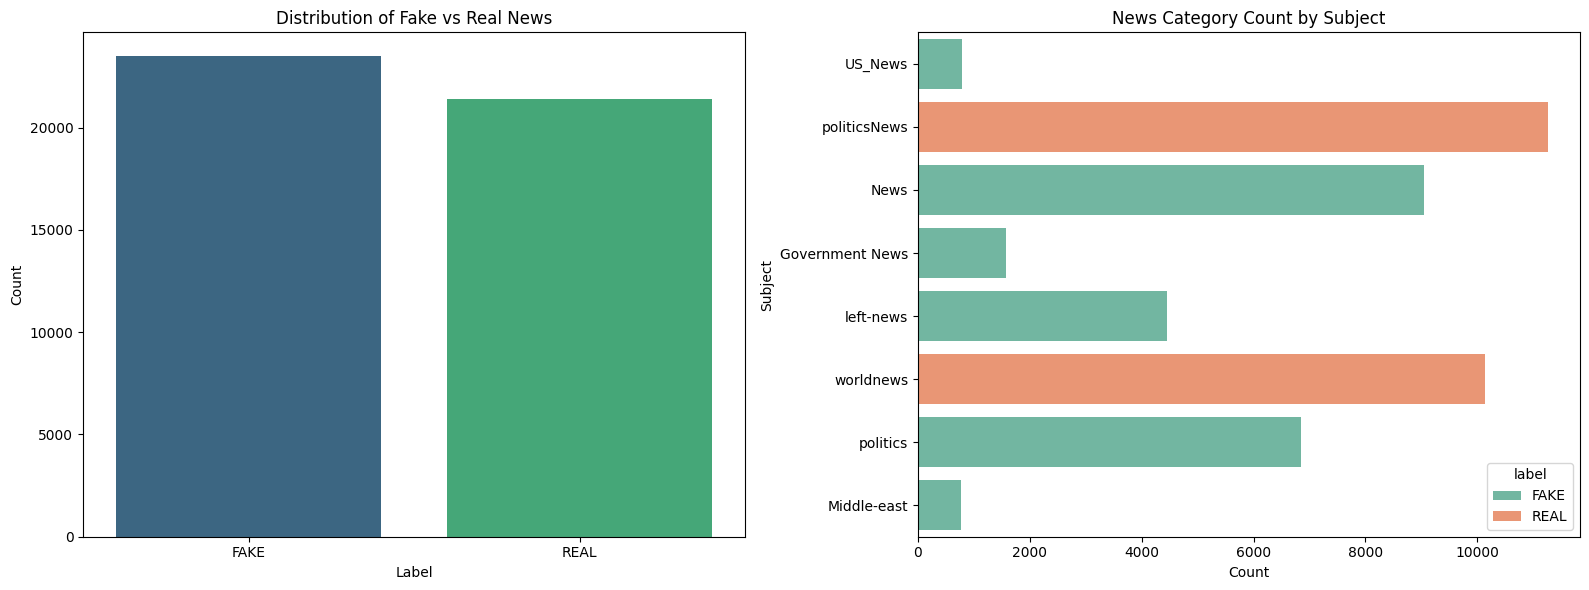

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Class Distribution
sns.countplot(x='label', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Fake vs Real News')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Count')

# Subject Distribution
sns.countplot(y='subject', data=df, hue='label', ax=axes[1], palette='Set2')
axes[1].set_title('News Category Count by Subject')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Subject')

plt.tight_layout()
plt.show()

### 3. Data Preprocessing & Splitting
We will clean the data by combining the title and the text body, then split the data into training and testing sets.

In [ ]:
# Combine title and text
df['total_text'] = df['title'] + " " + df['text']

# Define Features and Target
X = df['total_text']
y = df['label']

# Split the dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")

Train set size: 35918, Test set size: 8980


### 4. TF-IDF Vectorization & Model Training
We'll convert the textual data into numerical vectors using `TfidfVectorizer` and train a `PassiveAggressiveClassifier`, which is highly efficient for large-scale text classification tasks.

In [ ]:
# Initialize TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english', max_df=0.7)

# Fit and transform train set, transform test set
tfidf_train = tfidf_vectorizer.fit_transform(X_train)
tfidf_test = tfidf_vectorizer.transform(X_test)

# Initialize and train PassiveAggressiveClassifier
pac = PassiveAggressiveClassifier(max_iter=50, random_state=42)
pac.fit(tfidf_train, y_train)

PassiveAggressiveClassifier(max_iter=50, random_state=42)

Accuracy: 99.44%

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.99      0.99      0.99      4710
        REAL       0.99      0.99      0.99      4270

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



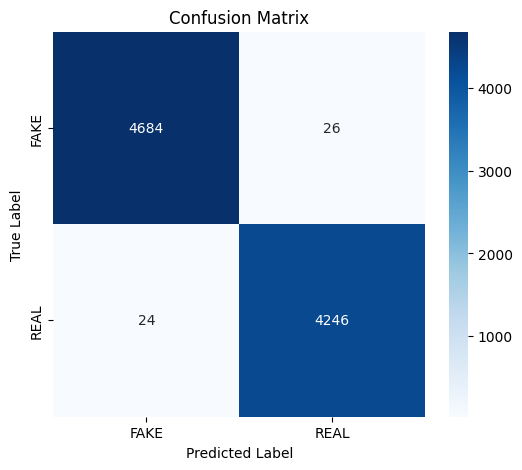

In [ ]:
# Predict on the test set
y_pred = pac.predict(tfidf_test)

# Calculate Accuracy
score = accuracy_score(y_test, y_pred)
print(f'Accuracy: {round(score*100,2)}%\n')

# Print Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Build Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=['FAKE', 'REAL'])

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['FAKE', 'REAL'], yticklabels=['FAKE', 'REAL'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### 6. Training Additional Algorithms: Logistic Regression & Naive Bayes
Let's train a **Logistic Regression** model and a **Multinomial Naive Bayes** model on the same vectorized text data to compare their performance with the Passive-Aggressive Classifier.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# 1. Initialize and train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(tfidf_train, y_train)
lr_pred = lr_model.predict(tfidf_test)
lr_accuracy = accuracy_score(y_test, lr_pred)

# 2. Initialize and train Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(tfidf_train, y_train)
nb_pred = nb_model.predict(tfidf_test)
nb_accuracy = accuracy_score(y_test, nb_pred)

print(f"Logistic Regression Accuracy: {round(lr_accuracy * 100, 2)}%")
print(f"Multinomial Naive Bayes Accuracy: {round(nb_accuracy * 100, 2)}%")

Logistic Regression Accuracy: 98.45%
Multinomial Naive Bayes Accuracy: 93.37%


### 7. Performance Comparison Visualization
Let's create a visual comparison of the accuracies of all three algorithms: Passive-Aggressive Classifier, Logistic Regression, and Naive Bayes.

/tmp/ipykernel_1051/1155725415.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=model_names, y=accuracies, palette='Set1')


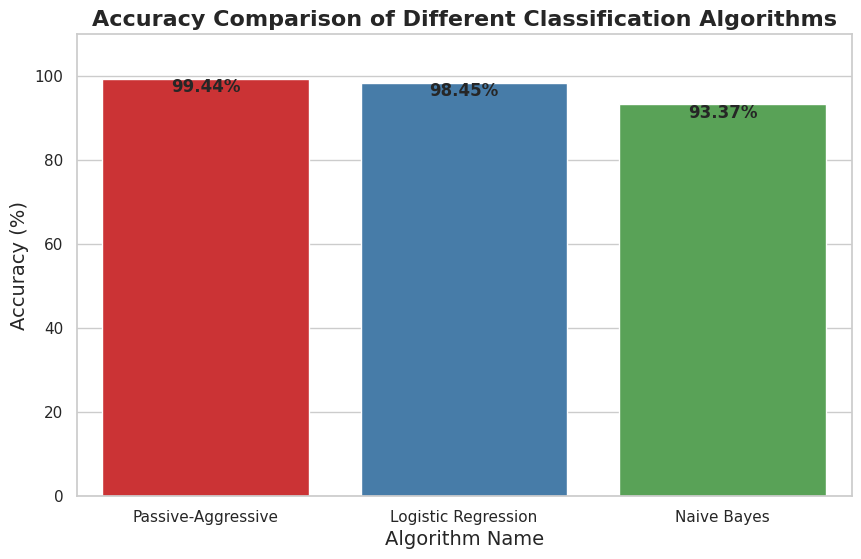

In [ ]:
# Prepare data for plotting
model_names = ['Passive-Aggressive', 'Logistic Regression', 'Naive Bayes']
accuracies = [score * 100, lr_accuracy * 100, nb_accuracy * 100]

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=model_names, y=accuracies, palette='Set1')

# Add values on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height() - 5),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                weight='bold',
                fontsize=12)

plt.title('Accuracy Comparison of Different Classification Algorithms', fontsize=16, weight='bold')
plt.xlabel('Algorithm Name', fontsize=14)
plt.ylabel('Accuracy (%)', fontsize=14)
plt.ylim(0, 110)
plt.show()